# 外国人「観光客」と「住民」の地域ギャップ分析

担当者：福田 直生

依頼元の組織：観光庁 観光地域振興部

読み手：観光地域振興部 政策企画課の皆様

この組織が知りたいこと：外国人「観光客（延べ宿泊者数）」が多い地域と、外国人「住民（人口）」が多い地域は一致しているのか？両者の地理的な偏りやギャップを分析し、観光客の地方誘客や滞在環境整備に活かせる知見を得たい。

In [40]:
import csv
import matplotlib.pyplot as plt

# Put japan.csv in the same folder as your notebook.
with open("japan.csv", encoding="utf-8-sig", newline="") as file:
    data = list(csv.DictReader(file))

print(len(data), "prefectures")
print(data[0]["Prefecture"], data[0]["総人口"])

47 prefectures
Hokkaido 5140000


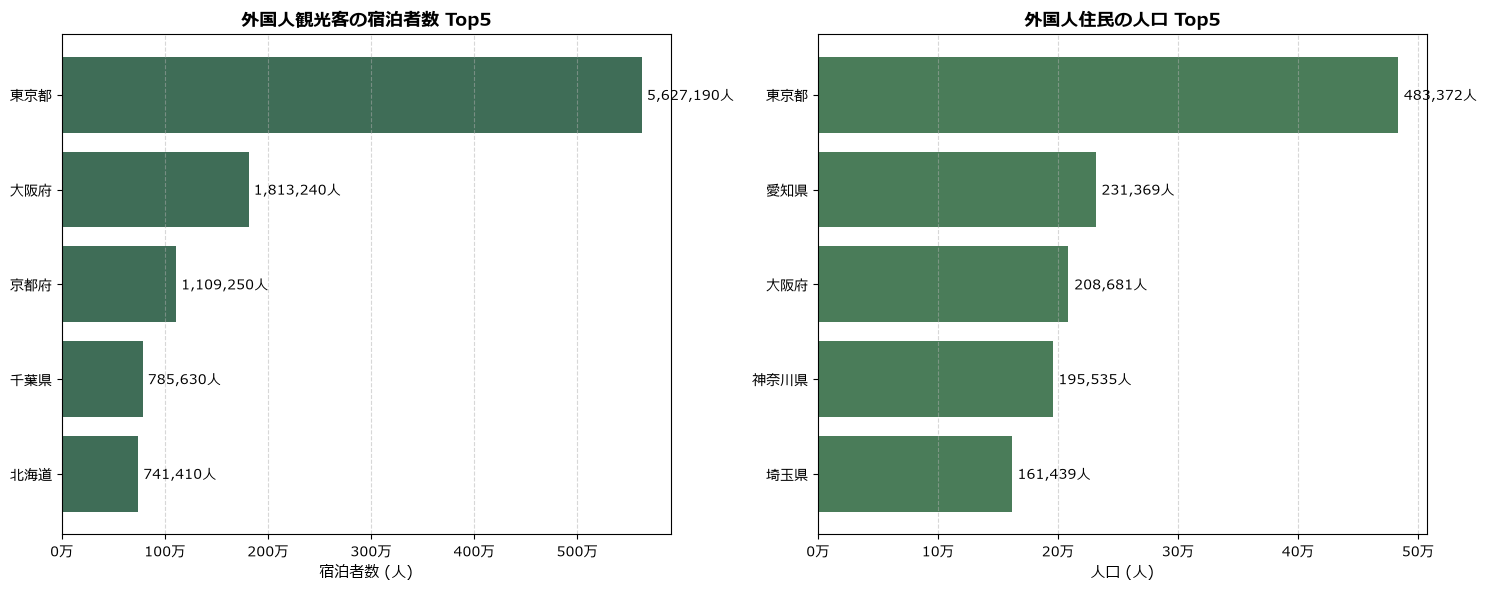

In [41]:
import csv
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker  # 軸の数値をキレイに調整するためのライブラリ

# 日本語フォント設定
plt.rcParams['font.sans-serif'] = ['Meiryo', 'MS Gothic', 'Yu Gothic', 'DejaVu Sans']

# データの読み込み
file_path = 'japan.csv'
with open(file_path, mode='r', encoding='utf-8') as f:
    reader = csv.reader(f)
    header = next(reader)
    rows = [row for row in reader]

pref_idx = header.index('都道府県')
foreign_pop_idx = header.index('外国人人口')
foreign_stay_idx = header.index('外国人延べ宿泊者数')

data = []
for r in rows:
    data.append({
        'Prefecture': r[pref_idx],
        'foreign_pop': int(r[foreign_pop_idx]),
        'foreign_stay': int(r[foreign_stay_idx])
    })

# 1. 観光客数（外国人延べ宿泊者数） Top5
top_stay = sorted(data, key=lambda row: row["foreign_stay"], reverse=True)[:5]
names_stay = [row["Prefecture"] for row in top_stay]
values_stay = [row["foreign_stay"] for row in top_stay]

# 2. 住民数（外国人人口） Top5
top_pop = sorted(data, key=lambda row: row["foreign_pop"], reverse=True)[:5]
names_pop = [row["Prefecture"] for row in top_pop]
values_pop = [row["foreign_pop"] for row in top_pop]

# グラフの描画枠を作成
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# --- 左側：外国人観光客の宿泊者数 Top5 ---
bars1 = ax1.barh(names_stay, values_stay, color="#3f6d57")
ax1.invert_yaxis()  # 上位を上に配置
ax1.set_title("外国人観光客の宿泊者数 Top5", fontsize=13, fontweight='bold')
ax1.set_xlabel("宿泊者数 (人)", fontsize=11)
ax1.grid(axis='x', linestyle='--', alpha=0.5)

# X軸の数値を「万人」単位でわかりやすく表示（100万ごとに区切る）
ax1.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{int(x/10000)}万'))

# バーの横に具体的な数値を表示
for bar in bars1:
    width = bar.get_width()
    ax1.text(width + 50000, bar.get_y() + bar.get_height()/2, f'{width:,.0f}人', 
             va='center', ha='left', fontsize=10, color='black')


# --- 右側：外国人住民の人口 Top5 ---
bars2 = ax2.barh(names_pop, values_pop, color="#4a7c59")
ax2.invert_yaxis()  # 上位を上に配置
ax2.set_title("外国人住民の人口 Top5", fontsize=13, fontweight='bold')
ax2.set_xlabel("人口 (人)", fontsize=11)
ax2.grid(axis='x', linestyle='--', alpha=0.5)

# X軸の数値を「万人」単位でわかりやすく表示
ax2.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{int(x/10000)}万'))

# バーの横に具体的な数値を表示
for bar in bars2:
    width = bar.get_width()
    ax2.text(width + 5000, bar.get_y() + bar.get_height()/2, f'{width:,.0f}人', 
             va='center', ha='left', fontsize=10, color='black')

plt.tight_layout()
plt.show()

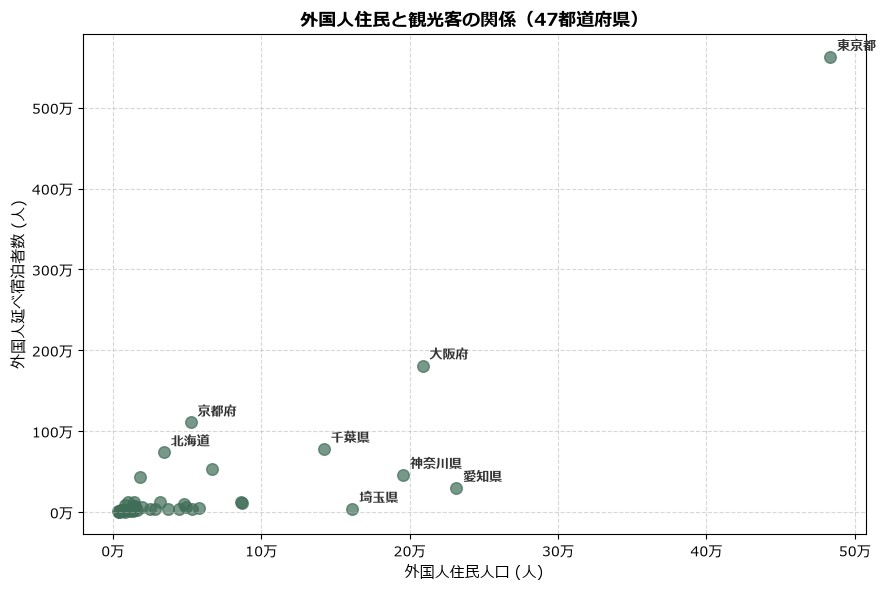

In [42]:
import csv
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker  # 軸の数値をキレイに調整する用

# 日本語フォント設定
plt.rcParams['font.sans-serif'] = ['Meiryo', 'MS Gothic', 'Yu Gothic', 'DejaVu Sans']

# データの読み込み
file_path = 'japan.csv'
with open(file_path, mode='r', encoding='utf-8') as f:
    reader = csv.reader(f)
    header = next(reader)
    rows = [row for row in reader]

pref_idx = header.index('都道府県')
foreign_pop_idx = header.index('外国人人口')
foreign_stay_idx = header.index('外国人延べ宿泊者数')

data = []
for r in rows:
    data.append({
        'Prefecture': r[pref_idx],
        'foreign_pop': int(r[foreign_pop_idx]),
        'foreign_stay': int(r[foreign_stay_idx])
    })

# データの抽出
prefs = [row["Prefecture"] for row in data]
foreign_pop = [row["foreign_pop"] for row in data]
foreign_stay = [row["foreign_stay"] for row in data]

# 散布図の描画
plt.figure(figsize=(9, 6))
plt.scatter(foreign_pop, foreign_stay, color="#3f6d57", alpha=0.7, s=70)

# 軸の数値を「万人」単位でわかりやすくフォーマット
plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{int(x/10000)}万'))
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{int(x/10000)}万'))

# 主要な都道府県にラベル（文字）を付ける
target_prefs = ['東京都', '大阪府', '京都府', '愛知県', '北海道', '千葉県', '神奈川県', '埼玉県']
for row in data:
    if row['Prefecture'] in target_prefs:
        # ラベルが重ならないよう、都市によって少し位置を微調整できます
        plt.annotate(row['Prefecture'], 
                     (row['foreign_pop'], row['foreign_stay']),
                     xytext=(5, 5), textcoords='offset points',
                     fontsize=9, fontweight='bold', color='#333333')

plt.xlabel("外国人住民人口 (人)", fontsize=11)
plt.ylabel("外国人延べ宿泊者数 (人)", fontsize=11)
plt.title("外国人住民と観光客の関係（47都道府県）", fontsize=13, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## 2. 読み込み・確認
本分析では、授業提供の都道府県別データ（japan.csv）を使用する。統計年次や詳細な定義が未確認であるため、現在の日本の実態を断定するものではなく、あくまで提供データに基づく相対的な傾向の把握を目的とする。

使用変数: 外国人人口（住民数：人）、外国人延べ宿泊者数（観光客数：人・泊）

---

## 3. 分析手順
外国人「観光客」と「住民」の分布が一致しているかを、以下の2段階で検証した。

1. **上位5地域のランキング比較（棒グラフ）**
   - 「外国人延べ宿泊者数」と「外国人人口」のそれぞれ上位5都道府県を抽出し、上位層における顔ぶれや規模感を比較する。
2. **47都道府県の全体傾向の把握（散布図）**
   - 横軸に「外国人人口（住民）」、縦軸に外国人延べ宿泊者数（観光客）をとった散布図を作成し、47都道府県全体の相関関係および「観光特化型」「定住特化型」といった地域ごとの特徴（クラスター）を可視化する。

---

## 4. 結果と解釈

### (1) 上位ランキングの比較結果
観光客上位: 東京、大阪、京都、千葉、北海道（観光地や主要空港を抱える地域が中心）

住民上位: 東京、愛知、大阪、神奈川、埼玉（大都市圏および製造業が盛んな地域が中心）

解釈: 上位層の顔ぶれに明確な違いがあり、観光客が集中する地域と住民が多く暮らす地域は一致していない。

### (2) 散布図から読み取れる地域特性のギャップ
メガシティ型: 東京都が住民・宿泊者数ともに他を圧倒し、一極集中が際立っている。

観光・交流特化型: 京都府や北海道など。住民数に対して宿泊者数が大きく上振れし、インバウンドの影響が大きい。

定住・就労特化型: 愛知県や埼玉県など。宿泊者数に対して外国人住民の割合が高く、就労・生活基盤としての定住傾向が強い。

---

## 5. 結論
(1) 問いへの答え
外国人「観光客」が多い地域と外国人「住民」が多い地域は必ずしも一致せず、観光・交流に特化した地域と、就労・生活基盤としての定住に特化した地域に明確に二極化している。

(2) 政策への示唆（観光庁への提言）
地域ごとの異なる実態を踏まえ、一律ではなく特性に応じた政策の使い分けが不可欠である。

* 観光・交流特化型（例：京都府、北海道など）: オーバーツーリズムへの対策や、持続可能な観光インフラ・受け入れ環境の高度化に重点を置く。

* 定住・就労特化型（例：愛知県、埼玉県など）: 観光振興だけでなく、外国人住民が円滑に暮らせる生活環境の整備、労働環境の改善、多言語での行政・生活支援などの定住支援を重視する。

(3) 分析の限界
本分析は授業提供の統計データに基づくものであり、単一時点の傾向把握に留まっている。そのため、季節による変動や、各地域の産業構造（観光業や製造業の比率など）の詳細な背景要因までを網羅しているわけではない。今後は、より多角的な時系列データや地域経済指標を交えた検証が望ましい。